# Quality assessment of the 2D reference labels

This notebook assesses the delivered 2D reference labels for both study sites without re-annotation. It quantifies coverage and class balance, geometry integrity, preservation through rasterisation and downsampling, registration to the predictor imagery, sensitivity to a 5 cm boundary shift, and separation on independent LiDAR height.

Agreement is reported as class-wise **IoU**, given throughout as **mean / median** pooled over tiles and classes. Both are shown because they disagree informatively: a mean well below its median means a single class or a few tiles are failing alone rather than the labels being uniformly poor, which is the case at both sites and for different reasons.

The available data do not support estimates of annotation accuracy against field truth or inter-annotator reproducibility because neither field labels nor repeat annotations are available. Delineation sensitivity is therefore reported as a bound on geometric uncertainty, not as observed agreement.


In [1]:
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd


def find_repo_root(start: Path) -> Path:
    marker = Path('phase_3_2D_imagery_prep/step_3_label_quality/label_qa.py')
    for candidate in [start, *start.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f'Could not locate repository root from {start}')


REPO_ROOT = find_repo_root(Path.cwd().resolve())
STEP_DIR = REPO_ROOT / 'phase_3_2D_imagery_prep' / 'step_3_label_quality'
if str(STEP_DIR) not in sys.path:
    sys.path.insert(0, str(STEP_DIR))

from label_qa import CLASS_LABELS, DEFAULT_BOUNDARY_M, read_annotations, wsl_path

SITES = [
    # `figure_tile` is the tile drawn by the centroid figure. 26 is one of only two
    # medium-site tiles whose label and predictor grids are offset from each other; on
    # the other thirteen the two footprints are identical and the figure shows nothing.
    {'site': 'site1_1_DD0001', 'condition': 'Medium', 'shp_subdir': 'annotations_shp',
     'figure_tile': '26'},
    {'site': 'site2_1_DD0011', 'condition': 'Low', 'shp_subdir': 'annotation_shp',
     'figure_tile': '25'},
]
FORCE_RERUN = False


def site_paths(config):
    base = wsl_path(rf"D:\paper2\data\calperumResearch\{config['site']}")
    mask = base / 'imagery' / 'inputs' / 'masks' / 'tiles_3072' / 'raw' / 'structure_class'
    raster = mask / 'annotation_raster'
    predictors = base / 'imagery' / 'inputs' / 'predictors' / 'tiles_3072'
    image = next((path for path in (
        predictors / 'multispec' / 'res_05' / 'stacked', predictors / 'stacked'
    ) if path.exists()), None)
    return {
        'shp': mask / config['shp_subdir'],
        'raster': raster,
        'coarse': raster / 'downsample_5cm_nearest',
        'image': image,
        'rgb': predictors / 'rgb',
        'las': base / 'lidar' / 'clipped' / 'raster' / 'z_norm' / 'csf',
        'out': base / 'lidar' / 'clipped' / 'validation' / 'label_quality',
    }


DATA = {}
for config in SITES:
    paths = site_paths(config)
    summary_csv = paths['out'] / f"{config['site']}_qa_summary.csv"
    issues_csv = paths['out'] / f"{config['site']}_qa_issues.csv"
    if FORCE_RERUN or not summary_csv.exists():
        command = [
            sys.executable, str(STEP_DIR / 'label_qa.py'),
            '--site', config['site'], '--site-condition', config['condition'],
            '--shp-dir', str(paths['shp']), '--raster-dir', str(paths['raster']),
            '--downsampled-dir', str(paths['coarse']), '--las-dir', str(paths['las']),
            *(['--image-dir', str(paths['image'])] if paths['image'] else []),
            '--output-dir', str(paths['out']),
        ]
        result = subprocess.run(command, text=True, capture_output=True)
        if result.returncode:
            raise RuntimeError(result.stderr[-3000:])

    summary = pd.read_csv(summary_csv)
    DATA[config['condition']] = {
        **config,
        'tiles': summary[~summary['Tile'].isin(['Average', 'Median'])].copy(),
        'average': summary[summary['Tile'] == 'Average'].iloc[0],
        'median': summary[summary['Tile'] == 'Median'].iloc[0],
        'issues': pd.read_csv(issues_csv),
    }

print('Loaded:', ', '.join(
    f"{condition} ({len(data['tiles'])} tiles)" for condition, data in DATA.items()
))

Loaded: Medium (15 tiles), Low (15 tiles)


In [2]:
from IPython.display import Markdown, display

# Each IoU family is one lossy step between the drawn polygon and what a model reads.
IOU_FAMILIES = {
    'Polygon -> 1 cm raster': 'IoU raster',
    '1 cm -> 5 cm raster': 'IoU 5 cm',
    'Label -> predictor grid': 'IoU imagery grid',
    'Delineation bound (+/-5 cm)': 'Delineation IoU',
}


def iou_values(tiles, prefix):
    """Every per-tile, per-class IoU under one prefix; classes absent from the site drop out."""
    columns = [f'{prefix} {name}' for name in CLASS_LABELS.values() if f'{prefix} {name}' in tiles]
    values = [tiles[c].dropna() for c in columns]
    values = [v for v in values if not v.empty]
    return pd.concat(values, ignore_index=True) if values else pd.Series(dtype=float)


def mean_median(tiles, prefix):
    """Mean and median pooled over tiles and classes. They part company when one class fails."""
    v = iou_values(tiles, prefix)
    return 'not measured' if v.empty else f'{v.mean():.3f} / {v.median():.3f}'


# 1. The headline: mean / median IoU at each step, per site.
iou_table = pd.DataFrame({
    f"{cond} ({d['site'].split('_')[-1]})": {
        step: mean_median(d['tiles'], prefix) for step, prefix in IOU_FAMILIES.items()
    } for cond, d in DATA.items()
})
iou_table.index.name = 'mean / median IoU'
display(iou_table)

# 2. Polygon -> raster per class, where a single failing class is visible rather than pooled.
per_class = pd.DataFrame({
    f"{cond} ({d['site'].split('_')[-1]})": {
        name: (f"{d['tiles'][f'IoU raster {name}'].mean():.3f} / "
               f"{d['tiles'][f'IoU raster {name}'].median():.3f}")
        for name in CLASS_LABELS.values()
        if f'IoU raster {name}' in d['tiles'] and d['tiles'][f'IoU raster {name}'].notna().any()
    } for cond, d in DATA.items()
}).fillna('absent from site')
per_class.index.name = 'Polygon -> 1 cm raster, mean / median'
display(per_class)

# 3. Context the IoU does not carry: how much of each tile is labelled, and how clean it is.
context = pd.DataFrame({
    f"{cond} ({d['site'].split('_')[-1]})": {
        'Tiles': f"{len(d['tiles'])}",
        'Labelled area (%)': f"{d['average']['Labelled area (%)']:.1f} / "
                             f"{d['median']['Labelled area (%)']:.1f}",
        'Polygons per tile': f"{d['average']['Polygons']:.0f} / {d['median']['Polygons']:.0f}",
        'Invalid geometries per tile': f"{d['average']['Invalid geometries']:.1f} / "
                                       f"{d['median']['Invalid geometries']:.1f}",
        'Cross-class overlap (%)': f"{d['average']['Cross-class overlap (%)']:.3f} / "
                                   f"{d['median']['Cross-class overlap (%)']:.3f}",
        'Height AUC': mean_median(d['tiles'], 'Height AUC'),
    } for cond, d in DATA.items()
})
context.index.name = 'mean / median across tiles'
display(context)

# 4. Per-feature displacement and IoU, after Haynes et al. (2025). RMSE and MAE answer
#    "how far did the feature move", the polygon IoU "how much of it survived" -- the class
#    IoU above pools both into one number and so cannot separate a shift from a loss.
STAGES = {'1 cm': 'the delivered 1 cm raster', '5 cm': 'the 5 cm label grid the models read',
          'imagery': 'the predictor grid'}
feature = pd.DataFrame({
    f"{cond} ({d['site'].split('_')[-1]})": {
        **{f'Centroid RMSE / MAE, {s} (m)':
           f"{d['tiles'][f'Centroid RMSE {s} (m)'].mean():.4f} / "
           f"{d['tiles'][f'Centroid MAE {s} (m)'].mean():.4f}" for s in STAGES},
        **{f'Polygon IoU mean / median, {s}':
           f"{d['tiles'][f'Polygon IoU mean {s}'].mean():.3f} / "
           f"{d['tiles'][f'Polygon IoU median {s}'].median():.3f}" for s in STAGES},
    } for cond, d in DATA.items()
})
feature.index.name = 'per feature, across tiles'
display(feature)

medium, low = DATA['Medium'], DATA['Low']
medium_offsets = int((medium['tiles']['5 cm grid offset (cm)'] > 0).sum())
low_woody = low['tiles']['IoU raster Woody debris']
low_others = iou_values(
    low['tiles'].drop(columns=['IoU raster Woody debris']), 'IoU raster')

response = f"""
## Quality assessment summary

The delivered 2D reference labels were assessed for both sites
({len(medium['tiles'])} medium-condition tiles and {len(low['tiles'])} low-condition tiles)
without re-annotation. Agreement is reported as class-wise IoU at each lossy step between the
drawn polygon and the array a model reads, pooled over tiles and classes and given as
**mean / median**; the two part company exactly where one class or a few tiles fail
differently from the rest, so the gap between them is itself a result.

Between the **polygon and the delivered 1 cm raster** the labels score
**{mean_median(medium['tiles'], 'IoU raster')}** at the medium site and
**{mean_median(low['tiles'], 'IoU raster')}** at the low site. The low site's mean sits well
below its median because one class fails alone: Woody debris scores
**{low_woody.mean():.3f}** where every other class stays above
**{low_others.min():.3f}**. That is stale shapefiles
retaining `unknown` polygons, not a rasterisation error -- the delivered raster the
experiments consume excludes them.

Through the **1 cm to 5 cm downsample** the labels score
**{mean_median(medium['tiles'], 'IoU 5 cm')}** and
**{mean_median(low['tiles'], 'IoU 5 cm')}**. At the medium site
**{medium_offsets} of {len(medium['tiles'])} tiles** carry a 1-4 cm grid offset that dilates
sparse classes during downsampling; the low site's grid is aligned on every tile.

Against the **predictor grid** the labels score
**{mean_median(medium['tiles'], 'IoU imagery grid')}** and
**{mean_median(low['tiles'], 'IoU imagery grid')}**. Medium-site predictors are
**{medium['average']['Imagery GSD (cm)']:.1f} cm** with an origin
**{medium['average']['Imagery grid offset (cm)']:.1f} cm** off the label grid; low-site
predictors are **{low['average']['Imagery GSD (cm)']:.1f} cm** against 5 cm labels
(**{low['average']['Label cells per imagery pixel']:.1f}** label cells per image pixel).
Labels should be warped directly onto each predictor grid before fitting and evaluation.

Annotation itself is internally consistent: cross-class overlap covers
**{medium['average']['Cross-class overlap (%)']:.3f}%** and
**{low['average']['Cross-class overlap (%)']:.3f}%** of labelled area, and invalid geometries
average **{medium['average']['Invalid geometries']:.1f}** and
**{low['average']['Invalid geometries']:.1f}** per tile, each logged individually for repair.

Position and overlap were then separated per feature, following Haynes et al. (2025), who
co-register UAS imaging spectroscopy to RGB and report both the RMSE/MAE of centroid
displacement and the mean/median IoU of digitised features. Each labelled polygon here is
compared against its own footprint on each grid the pipeline writes it to. Centroids barely
move -- RMSE **{medium['tiles']['Centroid RMSE imagery (m)'].mean():.3f} m** and
**{low['tiles']['Centroid RMSE imagery (m)'].mean():.3f} m** on the predictor grid, well
inside one cell -- while per-feature IoU falls to
**{medium['tiles']['Polygon IoU mean imagery'].mean():.3f}** and
**{low['tiles']['Polygon IoU mean imagery'].mean():.3f}**. The labels are therefore in the
right *place* and the wrong *shape*: individual features are eroded and dilated by
quantisation rather than shifted off their ground. That distinction matters for how the
labels are used, because a shift is correctable by a warp and a shape change is not. Note
that Haynes et al. compare two independent delineations of one feature, whereas only one
delineation exists here, so these columns bound the cost of the grids, not of the annotator.

No repeat annotation exists, so inter-annotator reproducibility and accuracy against field
truth are not claimed. In their place, a +/-{DEFAULT_BOUNDARY_M * 100:.0f} cm delineation
sensitivity is reported as a geometric floor (IoU
**{mean_median(medium['tiles'], 'Delineation IoU')}** and
**{mean_median(low['tiles'], 'Delineation IoU')}**) -- the agreement two delineations
disagreeing by one 5 cm cell everywhere would still reach -- and LiDAR height, never used to
make the labels, separates the classes descriptively (AUC
**{mean_median(medium['tiles'], 'Height AUC')}** and
**{mean_median(low['tiles'], 'Height AUC')}**).
"""
display(Markdown(response))


,Medium (DD0001),Low (DD0011)
mean / median IoU,,
Polygon -> 1 cm raster,0.924 / 0.934,0.679 / 0.957
1 cm -> 5 cm raster,0.806 / 0.804,0.996 / 0.997
Label -> predictor grid,0.784 / 0.782,0.930 / 0.941
Delineation bound (+/-5 cm),0.321 / 0.254,0.508 / 0.547


,Medium (DD0001),Low (DD0011)
"Polygon -> 1 cm raster, mean / median",,
Woody debris,0.853 / 0.868,0.014 / 0.000
Grass,0.920 / 0.927,absent from site
Shrub,0.939 / 0.940,0.980 / 0.980
Mallee,0.984 / 0.984,absent from site
Forb,absent from site,0.955 / 0.955


,Medium (DD0001),Low (DD0011)
mean / median across tiles,,
Tiles,15,15
Labelled area (%),20.2 / 18.9,35.1 / 34.3
Polygons per tile,408 / 399,413 / 432
Invalid geometries per tile,7.6 / 0.0,0.8 / 0.0
Cross-class overlap (%),0.021 / 0.000,0.161 / 0.058
Height AUC,0.563 / 0.559,0.499 / 0.476


,Medium (DD0001),Low (DD0011)
"per feature, across tiles",,
"Centroid RMSE / MAE, 1 cm (m)",0.0083 / 0.0025,0.0019 / 0.0013
"Centroid RMSE / MAE, 5 cm (m)",0.0158 / 0.0089,0.0069 / 0.0058
"Centroid RMSE / MAE, imagery (m)",0.0157 / 0.0087,0.0099 / 0.0072
"Polygon IoU mean / median, 1 cm",0.896 / 0.897,0.936 / 0.947
"Polygon IoU mean / median, 5 cm",0.809 / 0.803,0.878 / 0.899
"Polygon IoU mean / median, imagery",0.809 / 0.808,0.858 / 0.881



## Quality assessment summary

The delivered 2D reference labels were assessed for both sites
(15 medium-condition tiles and 15 low-condition tiles)
without re-annotation. Agreement is reported as class-wise IoU at each lossy step between the
drawn polygon and the array a model reads, pooled over tiles and classes and given as
**mean / median**; the two part company exactly where one class or a few tiles fail
differently from the rest, so the gap between them is itself a result.

Between the **polygon and the delivered 1 cm raster** the labels score
**0.924 / 0.934** at the medium site and
**0.679 / 0.957** at the low site. The low site's mean sits well
below its median because one class fails alone: Woody debris scores
**0.014** where every other class stays above
**0.934**. That is stale shapefiles
retaining `unknown` polygons, not a rasterisation error -- the delivered raster the
experiments consume excludes them.

Through the **1 cm to 5 cm downsample** the labels score
**0.806 / 0.804** and
**0.996 / 0.997**. At the medium site
**13 of 15 tiles** carry a 1-4 cm grid offset that dilates
sparse classes during downsampling; the low site's grid is aligned on every tile.

Against the **predictor grid** the labels score
**0.784 / 0.782** and
**0.930 / 0.941**. Medium-site predictors are
**5.0 cm** with an origin
**0.3 cm** off the label grid; low-site
predictors are **6.0 cm** against 5 cm labels
(**1.2** label cells per image pixel).
Labels should be warped directly onto each predictor grid before fitting and evaluation.

Annotation itself is internally consistent: cross-class overlap covers
**0.021%** and
**0.161%** of labelled area, and invalid geometries
average **7.6** and
**0.8** per tile, each logged individually for repair.

Position and overlap were then separated per feature, following Haynes et al. (2025), who
co-register UAS imaging spectroscopy to RGB and report both the RMSE/MAE of centroid
displacement and the mean/median IoU of digitised features. Each labelled polygon here is
compared against its own footprint on each grid the pipeline writes it to. Centroids barely
move -- RMSE **0.016 m** and
**0.010 m** on the predictor grid, well
inside one cell -- while per-feature IoU falls to
**0.809** and
**0.858**. The labels are therefore in the
right *place* and the wrong *shape*: individual features are eroded and dilated by
quantisation rather than shifted off their ground. That distinction matters for how the
labels are used, because a shift is correctable by a warp and a shape change is not. Note
that Haynes et al. compare two independent delineations of one feature, whereas only one
delineation exists here, so these columns bound the cost of the grids, not of the annotator.

No repeat annotation exists, so inter-annotator reproducibility and accuracy against field
truth are not claimed. In their place, a +/-5 cm delineation
sensitivity is reported as a geometric floor (IoU
**0.321 / 0.254** and
**0.508 / 0.547**) -- the agreement two delineations
disagreeing by one 5 cm cell everywhere would still reach -- and LiDAR height, never used to
make the labels, separates the classes descriptively (AUC
**0.563 / 0.559** and
**0.499 / 0.476**).


**Medium site (DD0001), tile 26**  ·  `label_centroids.png`

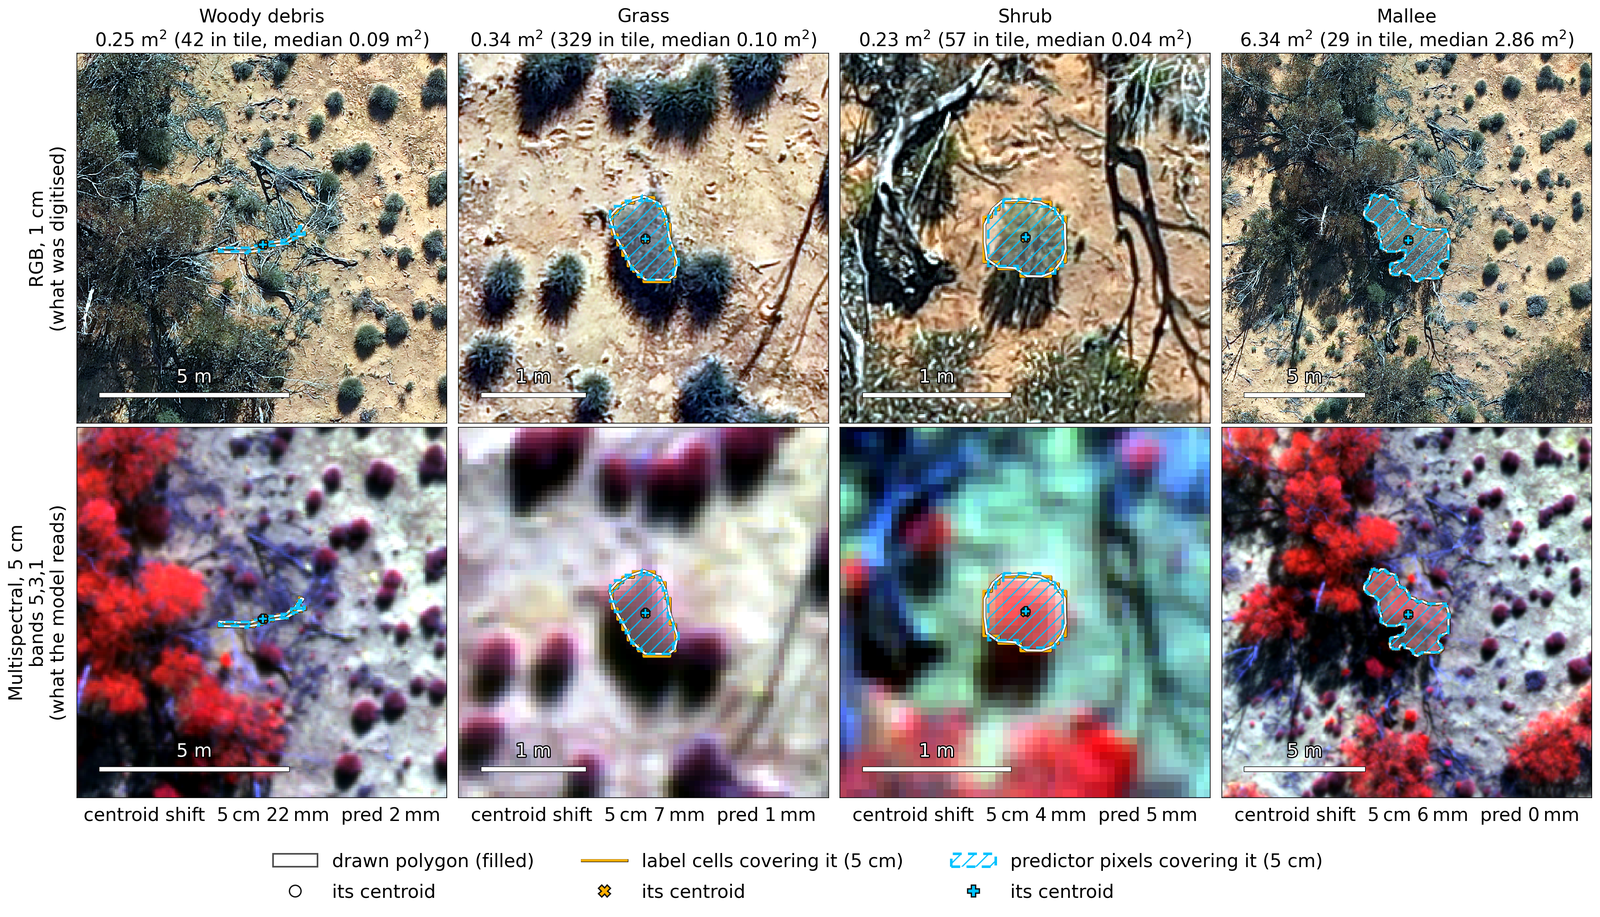

**Low site (DD0011), tile 25**  ·  `label_centroids_low.png`

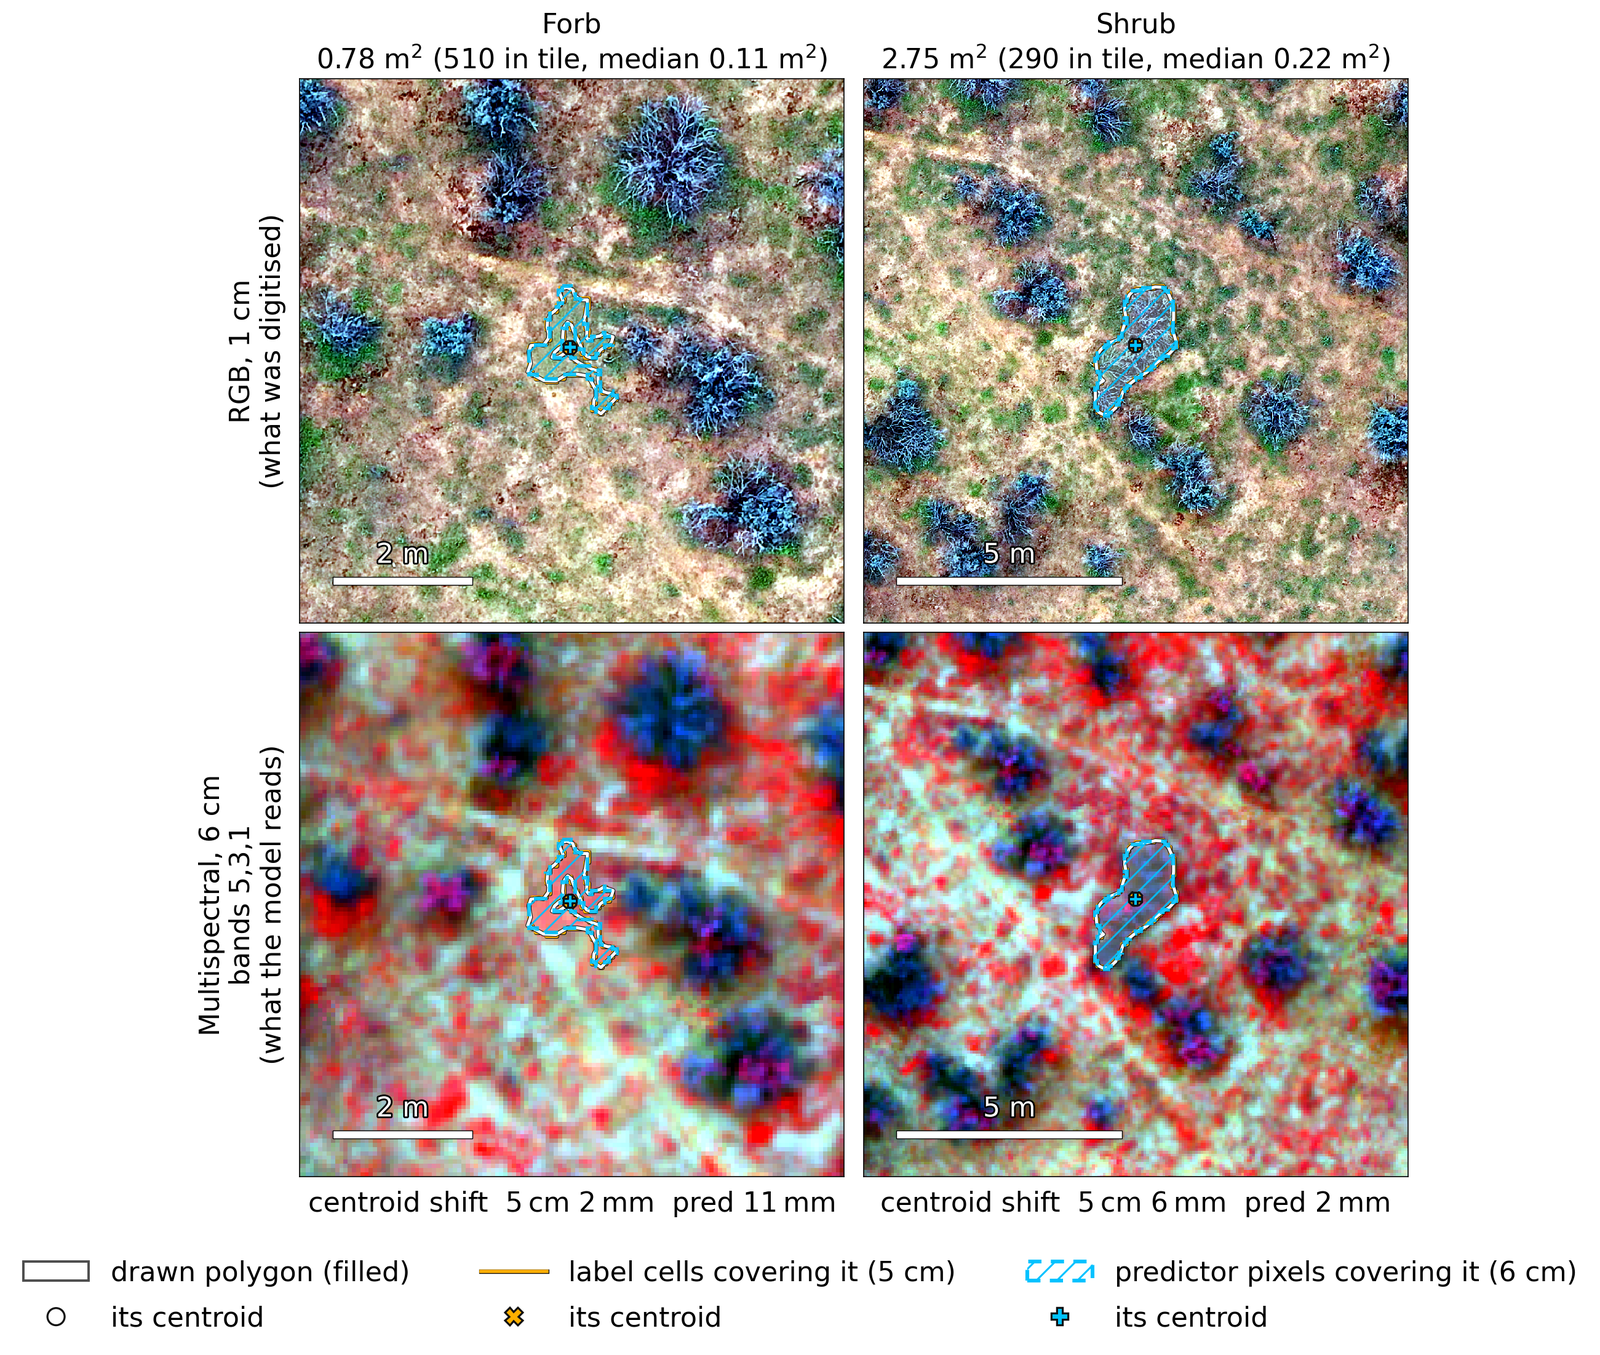

In [3]:
import io

from IPython.display import Image, display
from PIL import Image as PILImage

# The per-feature numbers above say centroids barely move while per-feature IoU falls.
# That is a claim about geometry, so it is drawn rather than asserted: one column per
# growth form, the 1 cm RGB the polygons were digitised on above the predictor stack the
# models read, with the drawn polygon, the label cells and the predictor pixels overlaid.
FIGURE_DIR = STEP_DIR
REDRAW = False
PREVIEW_WIDTH = 1600


def preview(path, width):
    """A downscaled copy for display. The file on disk stays at full resolution for
    the manuscript; embedding it verbatim would put ~10 MB of base64 in the notebook
    for every figure, which is slow to open and pointless on screen."""
    with PILImage.open(path) as image:
        if image.width > width:
            image = image.resize((width, round(image.height * width / image.width)),
                                 PILImage.LANCZOS)
        buffer = io.BytesIO()
        image.convert('RGB').save(buffer, format='PNG', optimize=True)
    return buffer.getvalue()

for config in SITES:
    paths = site_paths(config)
    stem = 'label_centroids' if config['condition'] == 'Medium' else 'label_centroids_low'
    png = FIGURE_DIR / f'{stem}.png'
    if REDRAW or not png.exists():
        command = [
            sys.executable, str(STEP_DIR / 'plot_centroids.py'),
            '--site', config['site'], '--tile', config['figure_tile'],
            '--shp-dir', str(paths['shp']), '--raster-dir', str(paths['raster']),
            '--downsampled-dir', str(paths['coarse']), '--image-dir', str(paths['image']),
            *(['--rgb-dir', str(paths['rgb'])] if paths['rgb'].exists() else []),
            '--output', str(FIGURE_DIR / stem),
        ]
        result = subprocess.run(command, text=True, capture_output=True)
        if result.returncode:
            raise RuntimeError(result.stderr[-3000:])
        print(result.stdout.strip().splitlines()[0] if result.stdout.strip() else '')

    display(Markdown(f"**{config['condition']} site ({config['site'].split('_')[-1]}), "
                     f"tile {config['figure_tile']}**  ·  `{png.name}`"))
    display(Image(data=preview(png, PREVIEW_WIDTH)))


## Why the label and predictor outlines look alike

In the figure above, the amber *label cells* and the cyan *predictor pixels* trace almost the
same staircase. That is not a drawing problem — it is the result. Both are the same polygon
quantised onto two grids, and at the medium site both grids are 5 cm; on most tiles they also
share an origin, so the two footprints are not merely similar but **identical**, and no styling
could separate them because there is nothing to separate.

The eye reads the silhouette, which a small origin shift barely moves. The IoU below reads the
cells, which it moves a great deal. It is scored on the **5 cm** grid — the resolution the
models and the 3D work consume — because a disagreement finer than one 5 cm cell is not
something either can act on. The two grid failures are also separated here because a
mean over all tiles would hide the difference between them: a **shifted origin** spares most
tiles completely and ruins a couple, while a **different pixel size** costs every feature on
every tile a little.


In [4]:
# `label_qa.py` measures this per polygon and writes three columns; reading them back
# keeps one implementation of the comparison rather than a second one here that can drift.
# It is scored on the 5 cm grid, the resolution the models and the 3D work consume:
# disagreement finer than one 5 cm cell is not something either can express.
def grids(row):
    """The two grids either interlock or they cannot, and the two failures behave
    differently: a shifted origin spares most tiles and ruins a couple, a different
    pixel size costs every feature on every tile. Pooling them would hide both."""
    if abs(row['Imagery GSD (cm)'] - 5.0) > 0.01:
        return f"{row['Imagery GSD (cm)']:.0f} cm pixels on 5 cm cells"
    return 'same origin' if row['Imagery grid offset (cm)'] < 0.1 else 'origins offset'


rows = []
for condition, data in DATA.items():
    tiles = data['tiles'].copy()
    tiles['Grids'] = tiles.apply(grids, axis=1)
    weight = tiles['Polygons measured for displacement']
    for name, block in tiles.groupby('Grids'):
        w = block['Polygons measured for displacement']
        rows.append({
            'Site': f"{condition} ({data['site'].split('_')[-1]})", 'Grids': name,
            'Tiles': len(block), 'Polygons': int(w.sum()),
            'Footprint IoU (mean / median)':
                f"{np.average(block['Label vs predictor IoU mean'], weights=w):.3f} / "
                f"{np.average(block['Label vs predictor IoU median'], weights=w):.3f}",
            'Identical cells (%)':
                f"{np.average(block['Label vs predictor identical (%)'], weights=w):.0f}",
        })

display(pd.DataFrame(rows).set_index(['Site', 'Grids']))


Tiles  Polygons  \
Site            Grids                                        
Medium (DD0001) origins offset                 2       692   
                same origin                   13      5311   
Low (DD0011)    6 cm pixels on 5 cm cells     15      6187   

                                          Footprint IoU (mean / median)  \
Site            Grids                                                     
Medium (DD0001) origins offset                            0.788 / 0.804   
                same origin                               1.000 / 1.000   
Low (DD0011)    6 cm pixels on 5 cm cells                 0.854 / 0.877   

                                          Identical cells (%)  
Site            Grids                                          
Medium (DD0001) origins offset                              0  
                same origin                                99  
Low (DD0011)    6 cm pixels on 5 cm cells                   1